# Analyze Crossover Geometry and Execution Conditions

## Goal

Test whether the 50% volume crossover is economically meaningful rather than treating it only as a forecasting target.

This notebook does four things:

1. Visualizes next-contract volume and open-interest migration across all ZN quarterly rolls.
2. Aligns rolls both by the inherited FND-relative panel index and by each roll's own volume crossover.
3. Fits an interpretable logistic migration curve to volume and OI for each roll:
   $
   S(t)=\frac{1}{1+e^{-k(t-\tau)}}
   $
   where $\tau$ is the fitted 50% midpoint and $k$ measures migration sharpness.
4. Maps the project's existing execution-cost and liquidity proxies around the realized volume crossover to ask whether the crossover coincides with favorable execution conditions.

No market data is downloaded. The notebook uses the standardized panel produced by `07_build_standardized_roll_panel.ipynb`.

### Important time convention

`bdays_to_fnd` is inherited from the existing project panel. The current project audit found that it counts observed UTC daily bars and includes Sunday-labeled rows. Therefore all durations below are **panel-observation units**, not yet a validated CME business-session calendar.


In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy.optimize import curve_fit
except ImportError as exc:
    raise ImportError("This notebook requires scipy. Install it with `pip install scipy`.") from exc

project_root = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "data" / "processed" / "zn_standardized_roll_panel.parquet").exists()), None)
if project_root is None:
    raise FileNotFoundError("Could not find data/processed/zn_standardized_roll_panel.parquet. Run 07_build_standardized_roll_panel.ipynb first.")

processed_dir = project_root / "data" / "processed"
results_dir = project_root / "results" / "crossover_geometry"
results_dir.mkdir(parents=True, exist_ok=True)

panel = pd.read_parquet(processed_dir / "zn_standardized_roll_panel.parquet").copy()
panel["date"] = pd.to_datetime(panel["date"])
panel = panel.sort_values(["roll_id", "date"]).reset_index(drop=True)

required = {"roll_id", "date", "bdays_to_fnd", "next_volume_share", "next_oi_share", "spread_volume", "spread_volume_share", "spread_intraday_range", "spread_roll_half_spread_cost_est", "spread_half_range_cost_proxy"}
missing = required - set(panel.columns)
if missing:
    raise ValueError(f"Standardized panel is missing: {sorted(missing)}")

print(f"{panel['roll_id'].nunique()} rolls | {len(panel):,} observations")
print(f"Panel-index range: {panel['bdays_to_fnd'].min()} to {panel['bdays_to_fnd'].max()}")

27 rolls | 837 observations
Panel-index range: -25 to 5


## 1. Define the realized volume and OI crossovers

For each roll, the realized crossover is the first panel observation for which the next contract's share exceeds 50%.

$$
\tau_r^V=\min\{t:S_{r,t}^V>0.5\},\qquad
\tau_r^{OI}=\min\{t:S_{r,t}^{OI}>0.5\}.
$$

These are descriptive events. They do not assume that 50% is the economically optimal time to roll.


In [3]:
def first_crossover_day(group, column):
    g = group.sort_values("bdays_to_fnd")
    hit = g.loc[g[column] > 0.5]
    if hit.empty:
        return np.nan
    return float(hit.iloc[0]["bdays_to_fnd"])

rows = []
for roll_id, g in panel.groupby("roll_id", sort=False):
    rows.append({
        "roll_id": roll_id,
        "volume_crossover_bday": first_crossover_day(g, "next_volume_share"),
        "oi_crossover_bday": first_crossover_day(g, "next_oi_share"),
    })
crossovers = pd.DataFrame(rows)
crossovers["oi_minus_volume_crossover"] = crossovers["oi_crossover_bday"] - crossovers["volume_crossover_bday"]

display(crossovers)
display(crossovers[["volume_crossover_bday", "oi_crossover_bday", "oi_minus_volume_crossover"]].describe())

,roll_id,volume_crossover_bday,oi_crossover_bday,oi_minus_volume_crossover
0,ZNH0->ZNM0,-1.0,-2.0,-1.0
1,ZNH1->ZNM1,-1.0,-2.0,-1.0
2,ZNH2->ZNM2,-2.0,-3.0,-1.0
3,ZNH3->ZNM3,-2.0,-4.0,-2.0
4,ZNH4->ZNM4,-1.0,-4.0,-3.0
5,ZNH5->ZNM5,-2.0,-3.0,-1.0
6,ZNH6->ZNM6,-2.0,-2.0,0.0
7,ZNM0->ZNU0,-1.0,-2.0,-1.0
8,ZNM1->ZNU1,-3.0,-4.0,-1.0
9,ZNM2->ZNU2,-3.0,-4.0,-1.0


,volume_crossover_bday,oi_crossover_bday,oi_minus_volume_crossover
count,27.000000,27.000000,27.000000
mean,-2.037037,-3.444444,-1.407407
std,0.587137,1.050031,0.971092
min,-3.000000,-5.000000,-3.000000
25%,-2.000000,-4.000000,-2.000000
50%,-2.000000,-3.000000,-1.000000
75%,-2.000000,-3.000000,-1.000000
max,-1.000000,-2.000000,0.000000


## 2. FND-aligned migration maps

Every roll is drawn as a thin line, with a cross-roll median and interquartile range. This answers: **when, relative to FND, does migration normally happen?**

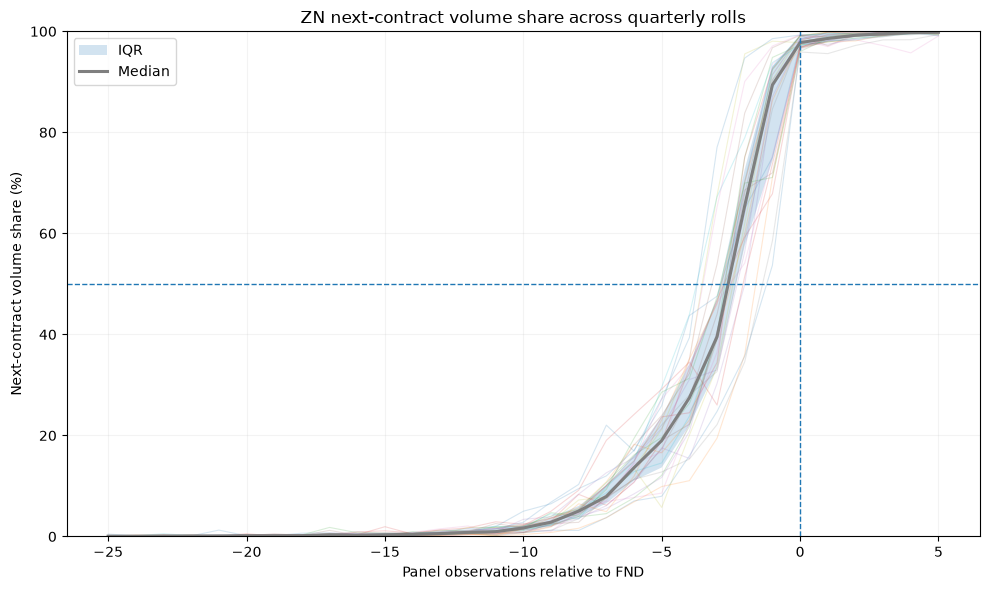

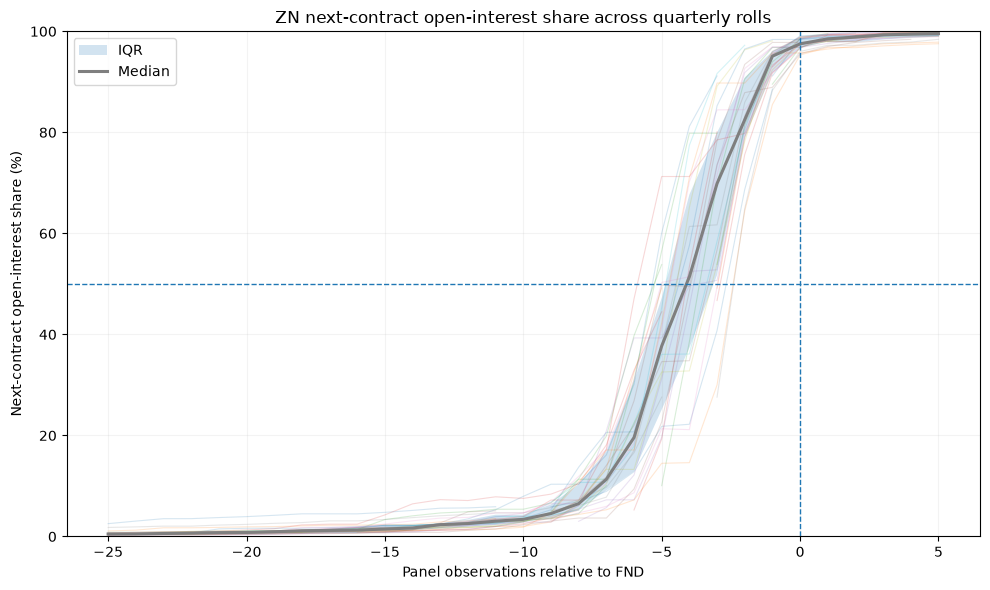

In [4]:
def plot_fnd_aligned(column, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(10, 6))
    for _, g in panel.groupby("roll_id"):
        g = g.sort_values("bdays_to_fnd")
        ax.plot(g["bdays_to_fnd"], g[column] * 100, linewidth=0.8, alpha=0.18)
    q = panel.groupby("bdays_to_fnd")[column].quantile([0.25, 0.50, 0.75]).unstack().sort_index() * 100
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.20, label="IQR")
    ax.plot(q.index, q[0.50], linewidth=2.2, label="Median")
    ax.axhline(50, linestyle="--", linewidth=1)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Panel observations relative to FND")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 100)
    ax.legend()
    ax.grid(alpha=0.15)
    fig.tight_layout()
    fig.savefig(results_dir / filename, dpi=180)
    plt.show()

plot_fnd_aligned("next_volume_share", "ZN next-contract volume share across quarterly rolls", "Next-contract volume share (%)", "fnd_aligned_volume_share.png")
plot_fnd_aligned("next_oi_share", "ZN next-contract open-interest share across quarterly rolls", "Next-contract open-interest share (%)", "fnd_aligned_oi_share.png")

## 3. Crossover-aligned migration maps

Shift each roll so its own realized **volume crossover** occurs at event time zero:

$$
u=t-\tau_r^V.
$$

This removes calendar-timing variation and focuses on local migration geometry. The volume plot shows how abrupt the transition is; the OI plot shows whether positioning tends to lead or lag the volume event.


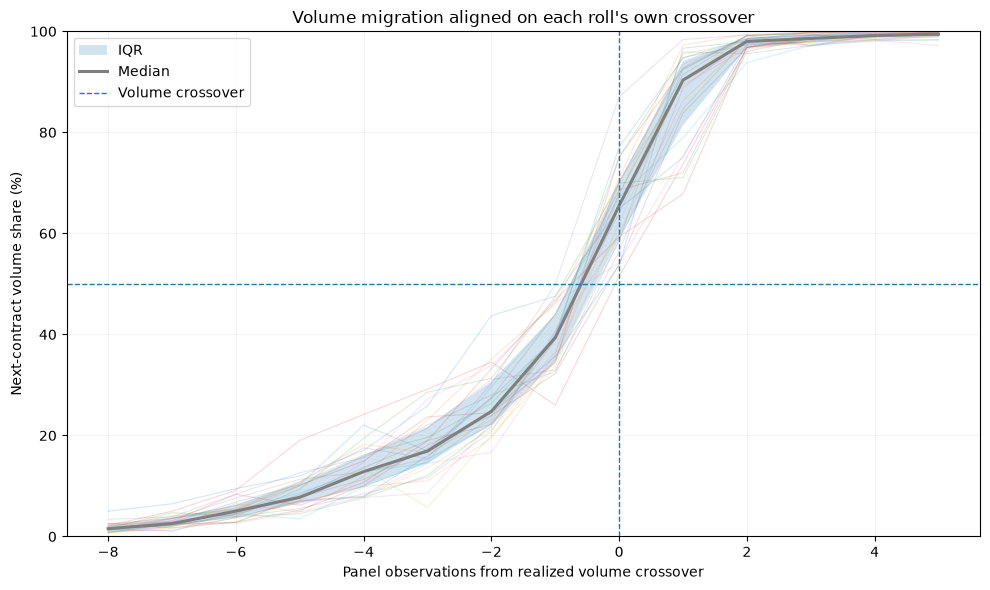

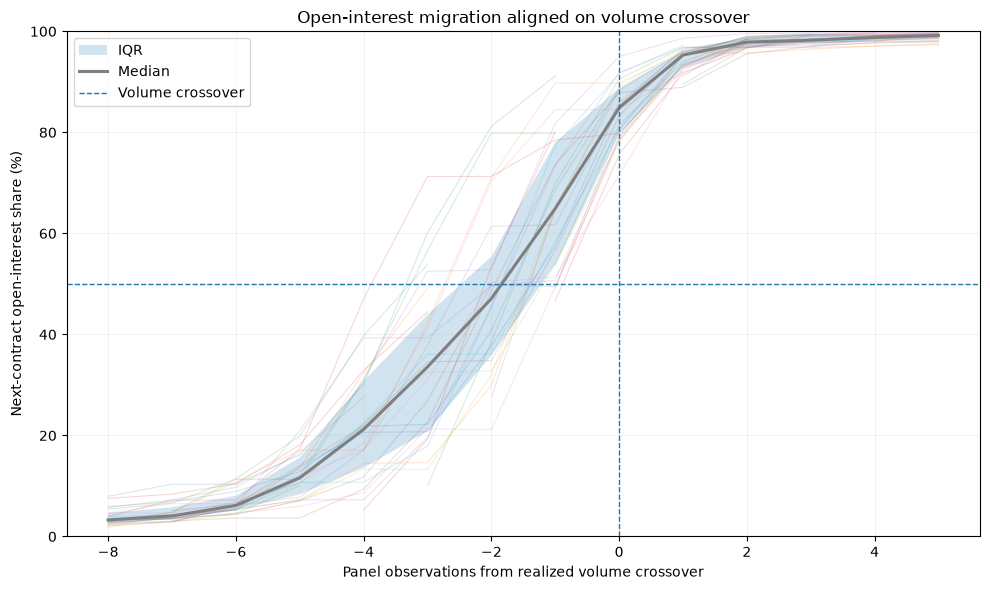

In [5]:
event_panel = panel.merge(crossovers[["roll_id", "volume_crossover_bday"]], on="roll_id", how="left")
event_panel["event_time"] = event_panel["bdays_to_fnd"] - event_panel["volume_crossover_bday"]

def plot_event_aligned(column, title, ylabel, filename, event_window=(-8, 5)):
    use = event_panel.loc[event_panel["event_time"].between(event_window[0], event_window[1])].copy()
    fig, ax = plt.subplots(figsize=(10, 6))
    for _, g in use.groupby("roll_id"):
        g = g.sort_values("event_time")
        ax.plot(g["event_time"], g[column] * 100, linewidth=0.8, alpha=0.18)
    q = use.groupby("event_time")[column].quantile([0.25, 0.50, 0.75]).unstack().sort_index() * 100
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.20, label="IQR")
    ax.plot(q.index, q[0.50], linewidth=2.2, label="Median")
    ax.axhline(50, linestyle="--", linewidth=1)
    ax.axvline(0, linestyle="--", linewidth=1, label="Volume crossover")
    ax.set_title(title)
    ax.set_xlabel("Panel observations from realized volume crossover")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 100)
    ax.legend()
    ax.grid(alpha=0.15)
    fig.tight_layout()
    fig.savefig(results_dir / filename, dpi=180)
    plt.show()

plot_event_aligned("next_volume_share", "Volume migration aligned on each roll's own crossover", "Next-contract volume share (%)", "crossover_aligned_volume_share.png")
plot_event_aligned("next_oi_share", "Open-interest migration aligned on volume crossover", "Next-contract open-interest share (%)", "crossover_aligned_oi_share.png")

## 4. Fit an interpretable migration curve

Use a two-parameter logistic curve rather than a generic spline:

$$
S(t)=\frac{1}{1+e^{-k(t-\tau)}}.
$$

- $\tau$: fitted midpoint, where the curve reaches 50%.
- $k$: sharpness. Larger $k$ means faster migration through the middle of the transition.

The raw paths are not forced to be monotone, so RMSE is retained as a goodness-of-fit diagnostic. A poor fit should be reported rather than hidden.


In [6]:
def logistic(x, tau, k):
    z = np.clip(-k * (x - tau), -60, 60)
    return 1.0 / (1.0 + np.exp(z))

def fit_logistic(group, column, measure):
    g = group[["roll_id", "bdays_to_fnd", column]].dropna().sort_values("bdays_to_fnd")
    if len(g) < 8:
        return None
    x = g["bdays_to_fnd"].to_numpy(dtype=float)
    y = g[column].to_numpy(dtype=float)
    if np.nanmax(y) - np.nanmin(y) < 0.20:
        return None
    tau0 = float(x[int(np.argmin(np.abs(y - 0.5)))])
    try:
        params, _ = curve_fit(logistic, x, y, p0=[tau0, 1.0], bounds=([x.min() - 5, 0.01], [x.max() + 5, 10.0]), maxfev=20000)
    except Exception as exc:
        warnings.warn(f"{g.iloc[0]['roll_id']} {measure}: {exc}")
        return None
    tau, k = map(float, params)
    fitted = logistic(x, tau, k)
    rmse = float(np.sqrt(np.mean((y - fitted) ** 2)))
    return {"roll_id": g.iloc[0]["roll_id"], "measure": measure, "tau_fitted": tau, "k_sharpness": k, "rmse": rmse, "n_obs": len(g)}

fits = []
for roll_id, g in panel.groupby("roll_id", sort=False):
    for column, measure in [("next_volume_share", "volume"), ("next_oi_share", "oi")]:
        result = fit_logistic(g, column, measure)
        if result is not None:
            fits.append(result)
fits = pd.DataFrame(fits)

fit_wide = fits.pivot(index="roll_id", columns="measure", values=["tau_fitted", "k_sharpness", "rmse"]).copy()
fit_wide.columns = ["_".join(col) for col in fit_wide.columns]
fit_wide = fit_wide.reset_index()

geometry = crossovers.merge(fit_wide, on="roll_id", how="left")
geometry["fitted_oi_minus_volume_tau"] = geometry["tau_fitted_oi"] - geometry["tau_fitted_volume"]
geometry["oi_to_volume_sharpness_ratio"] = geometry["k_sharpness_oi"] / geometry["k_sharpness_volume"]

display(geometry)
display(geometry[["tau_fitted_volume", "tau_fitted_oi", "k_sharpness_volume", "k_sharpness_oi", "fitted_oi_minus_volume_tau", "oi_to_volume_sharpness_ratio", "rmse_volume", "rmse_oi"]].describe())

fits.to_csv(results_dir / "logistic_fits.csv", index=False)
geometry.to_csv(results_dir / "roll_level_geometry.csv", index=False)

,roll_id,volume_crossover_bday,oi_crossover_bday,oi_minus_volume_crossover,tau_fitted_oi,tau_fitted_volume,k_sharpness_oi,k_sharpness_volume,rmse_oi,rmse_volume,fitted_oi_minus_volume_tau,oi_to_volume_sharpness_ratio
0,ZNH0->ZNM0,-1.0,-2.0,-1.0,-2.874981,-1.626271,0.794322,0.968828,0.045127,0.040066,-1.248710,0.819879
1,ZNH1->ZNM1,-1.0,-2.0,-1.0,-2.465372,-1.739482,1.081640,1.254953,0.031590,0.028873,-0.725890,0.861897
2,ZNH2->ZNM2,-2.0,-3.0,-1.0,-3.621132,-2.862325,1.358251,1.164735,0.024936,0.022016,-0.758807,1.166145
3,ZNH3->ZNM3,-2.0,-4.0,-2.0,-4.039873,-2.800063,1.367892,0.669627,0.018592,0.030188,-1.239810,2.042766
4,ZNH4->ZNM4,-1.0,-4.0,-3.0,-3.786892,-2.325015,0.789957,1.036363,0.030640,0.037772,-1.461877,0.762240
5,ZNH5->ZNM5,-2.0,-3.0,-1.0,-3.788266,-2.839833,0.709379,0.925033,0.038156,0.032634,-0.948433,0.766868
6,ZNH6->ZNM6,-2.0,-2.0,0.0,-3.122517,-2.739112,1.084017,1.146385,0.031258,0.025371,-0.383405,0.945596
7,ZNM0->ZNU0,-1.0,-2.0,-1.0,-2.887720,-1.649844,0.687501,0.947057,0.055237,0.042036,-1.237876,0.725935
8,ZNM1->ZNU1,-3.0,-4.0,-1.0,-4.510563,-3.709179,1.193099,1.122539,0.025063,0.029128,-0.801384,1.062857
9,ZNM2->ZNU2,-3.0,-4.0,-1.0,-4.907470,-3.836988,1.190926,0.789371,0.025681,0.012508,-1.070481,1.508702


,tau_fitted_volume,tau_fitted_oi,k_sharpness_volume,k_sharpness_oi,fitted_oi_minus_volume_tau,oi_to_volume_sharpness_ratio,rmse_volume,rmse_oi
count,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000
mean,-2.877084,-4.155780,0.889483,0.863281,-1.278697,1.011325,0.032868,0.033058
std,0.594238,0.757027,0.192194,0.245053,0.499017,0.357879,0.009969,0.009561
min,-4.074580,-5.454716,0.558035,0.508185,-2.680173,0.565627,0.012508,0.017606
25%,-3.151841,-4.685604,0.756804,0.694953,-1.490424,0.744087,0.027122,0.027641
50%,-2.839833,-4.226765,0.889507,0.794322,-1.237876,0.932211,0.031282,0.030640
75%,-2.732250,-3.787579,1.025050,1.043448,-1.004470,1.213014,0.038919,0.040227
max,-1.626271,-2.465372,1.254953,1.367892,-0.383405,2.042766,0.060682,0.055237


## 5. Map execution/liquidity proxies around volume crossover

The project does not currently contain observed bid/ask quotes, so these remain explicitly labeled as **proxies**:

- `spread_roll_half_spread_cost_est`: Roll-style implied half-spread estimate.
- `spread_half_range_cost_proxy`: half the calendar-spread daily high-low range.
- `spread_volume_share`: observed calendar-spread activity share.

Also construct a simple price-impact/illiquidity proxy:

$$
I_t=\frac{|\Delta P_t|}{V_t}\times100{,}000.
$$

Lower values mean less spread-price movement per 100,000 spread contracts. This is **not** a transaction-cost estimator.


In [7]:
if "spread_price_change" not in event_panel.columns:
    if "spread_close" not in event_panel.columns:
        raise ValueError("Need either spread_price_change or spread_close in the standardized panel.")
    event_panel["spread_price_change"] = event_panel.groupby("roll_id")["spread_close"].diff()

event_panel["spread_impact_per_100k"] = np.where(event_panel["spread_volume"] > 0, event_panel["spread_price_change"].abs() * 100000 / event_panel["spread_volume"], np.nan)

EVENT_MIN, EVENT_MAX = -5, 3
event_window = event_panel.loc[event_panel["event_time"].between(EVENT_MIN, EVENT_MAX)].copy()
metrics = ["spread_roll_half_spread_cost_est", "spread_half_range_cost_proxy", "spread_volume_share", "spread_impact_per_100k"]

parts = []
for metric in metrics:
    s = event_window.groupby("event_time")[metric].agg(["count", "mean", "median"]).reset_index()
    q = event_window.groupby("event_time")[metric].quantile([0.25, 0.75]).unstack().reset_index().rename(columns={0.25: "q25", 0.75: "q75"})
    s = s.merge(q, on="event_time", how="left")
    s.insert(0, "metric", metric)
    parts.append(s)
event_summary = pd.concat(parts, ignore_index=True)
display(event_summary)
event_summary.to_csv(results_dir / "event_time_liquidity_summary.csv", index=False)

,metric,event_time,count,mean,median,q25,q75
0,spread_roll_half_spread_cost_est,-5.0,20,0.006389,0.005764,0.003863,0.006939
1,spread_roll_half_spread_cost_est,-4.0,19,0.006576,0.005208,0.004346,0.007612
2,spread_roll_half_spread_cost_est,-3.0,20,0.007035,0.005615,0.005142,0.007886
3,spread_roll_half_spread_cost_est,-2.0,20,0.007328,0.006458,0.005058,0.008820
4,spread_roll_half_spread_cost_est,-1.0,23,0.006423,0.005938,0.004346,0.007554
5,spread_roll_half_spread_cost_est,0.0,21,0.007017,0.006791,0.004034,0.008479
6,spread_roll_half_spread_cost_est,1.0,21,0.007219,0.006163,0.004511,0.009096
7,spread_roll_half_spread_cost_est,2.0,19,0.008326,0.006791,0.003773,0.011221
8,spread_roll_half_spread_cost_est,3.0,15,0.009127,0.006163,0.004910,0.014025
9,spread_half_range_cost_proxy,-5.0,27,0.010995,0.011719,0.007812,0.011719


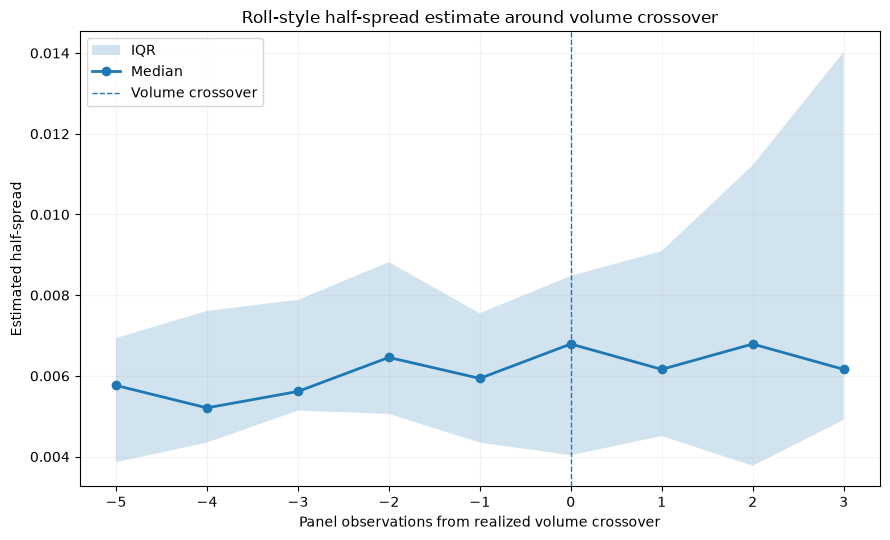

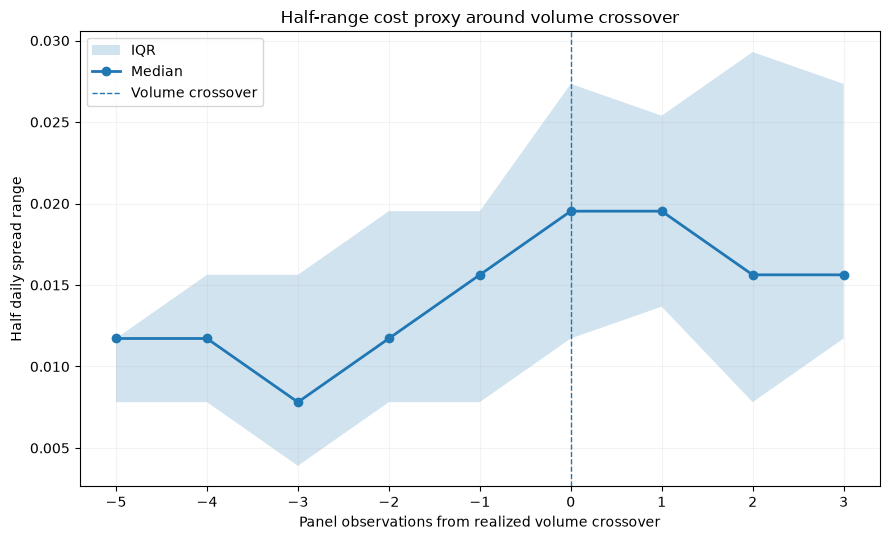

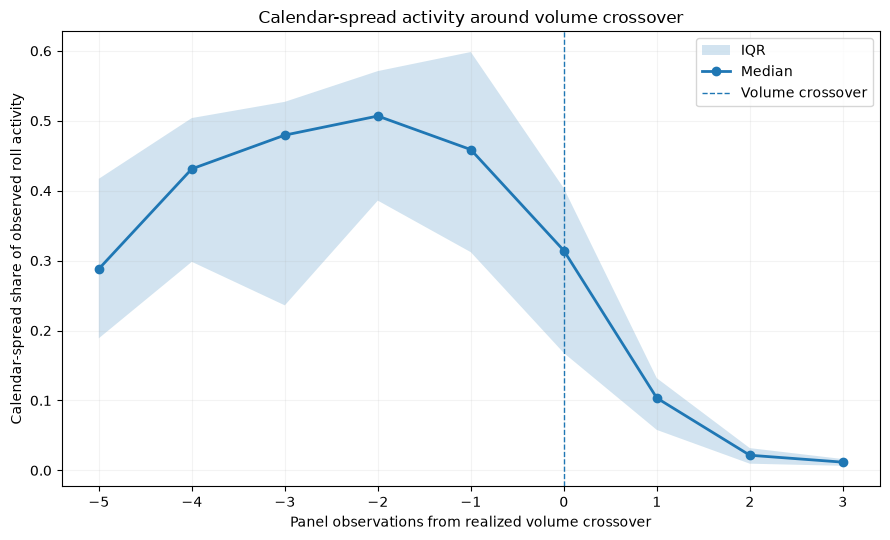

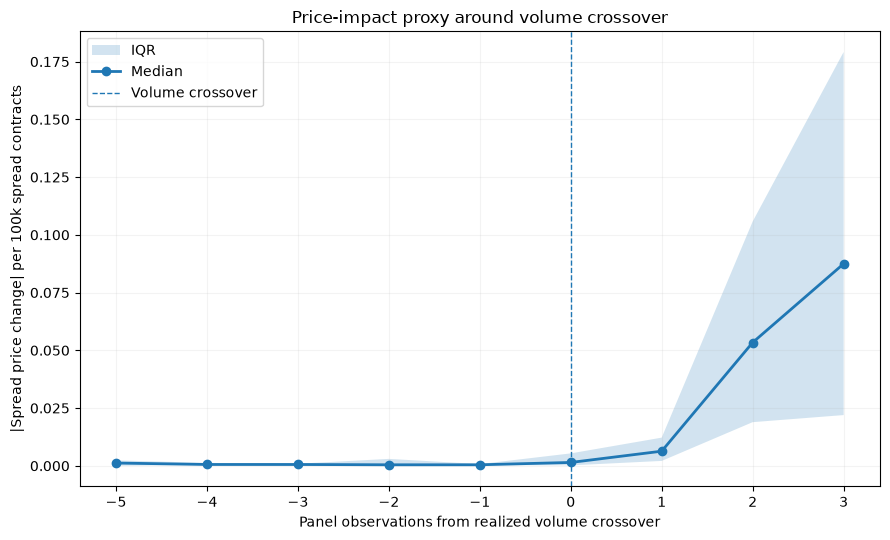

In [8]:
def plot_event_metric(metric, title, ylabel, filename):
    s = event_summary.loc[event_summary["metric"] == metric].sort_values("event_time")
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.fill_between(s["event_time"], s["q25"], s["q75"], alpha=0.20, label="IQR")
    ax.plot(s["event_time"], s["median"], marker="o", linewidth=2, label="Median")
    ax.axvline(0, linestyle="--", linewidth=1, label="Volume crossover")
    ax.set_title(title)
    ax.set_xlabel("Panel observations from realized volume crossover")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.15)
    fig.tight_layout()
    fig.savefig(results_dir / filename, dpi=180)
    plt.show()

plot_event_metric("spread_roll_half_spread_cost_est", "Roll-style half-spread estimate around volume crossover", "Estimated half-spread", "event_roll_half_spread.png")
plot_event_metric("spread_half_range_cost_proxy", "Half-range cost proxy around volume crossover", "Half daily spread range", "event_half_range_proxy.png")
plot_event_metric("spread_volume_share", "Calendar-spread activity around volume crossover", "Calendar-spread share of observed roll activity", "event_spread_volume_share.png")
plot_event_metric("spread_impact_per_100k", "Price-impact proxy around volume crossover", "|Spread price change| per 100k spread contracts", "event_price_impact_proxy.png")

## 6. Compare crossover against simple calendar benchmarks

Compare realized volume crossover against fixed panel-index rules -5, -3, and -1 relative to FND. This is descriptive because realized crossover uses hindsight. Its purpose is to test whether the crossover itself is a sensible economic target.

In [9]:
def nearest_row(group, target_bday):
    g = group.copy()
    g["distance"] = (g["bdays_to_fnd"] - target_bday).abs()
    return g.sort_values(["distance", "date"]).iloc[0]

rows = []
for roll_id, g in event_panel.groupby("roll_id", sort=False):
    cross = g["volume_crossover_bday"].iloc[0]
    if pd.isna(cross):
        continue
    targets = {"fixed_-5": -5, "fixed_-3": -3, "fixed_-1": -1, "realized_volume_crossover": float(cross)}
    for rule, target in targets.items():
        row = nearest_row(g, target)
        rows.append({
            "roll_id": roll_id, "rule": rule, "target_bday": target, "selected_bday": row["bdays_to_fnd"],
            "spread_roll_half_spread_cost_est": row["spread_roll_half_spread_cost_est"],
            "spread_half_range_cost_proxy": row["spread_half_range_cost_proxy"],
            "spread_volume_share": row["spread_volume_share"],
            "spread_impact_per_100k": row["spread_impact_per_100k"],
        })
benchmarks = pd.DataFrame(rows)
benchmark_summary = benchmarks.groupby("rule")[metrics].agg(["count", "mean", "median"])
display(benchmark_summary)
benchmarks.to_csv(results_dir / "benchmark_roll_conditions.csv", index=False)
benchmark_summary.to_csv(results_dir / "benchmark_roll_conditions_summary.csv")

spread_roll_half_spread_cost_est            \
                                                     count      mean   
rule                                                                   
fixed_-1                                                21  0.007064   
fixed_-3                                                23  0.006351   
fixed_-5                                                20  0.006735   
realized_volume_crossover                               21  0.007017   

                                    spread_half_range_cost_proxy            \
                             median                        count      mean   
rule                                                                         
fixed_-1                   0.006325                           27  0.018808   
fixed_-3                   0.005337                           27  0.017940   
fixed_-5                   0.006004                           27  0.011429   
realized_volume_crossover  0.006791                           27  0.021701   

                                    spread_volume_share                      \
                             median               count      mean    median   
rule                                                                          
fixed_-1                   0.019531                  27  0.111753  0.113480   
fixed_-3                   0.015625                  27  0.444437  0.458793   
fixed_-5                   0.007812                  27  0.327929  0.439585   
realized_volume_crossover  0.019531                  27  0.286051  0.314433   

                          spread_impact_per_100k                      
                                           count      mean    median  
rule                                                                  
fixed_-1                                      27  0.272540  0.005361  
fixed_-3                                      27  0.010395  0.000391  
fixed_-5                                      27  0.497236  0.000830  
realized_volume_crossover                     27  0.019328  0.001450

## 7. Interpretation

### Main finding

The 50% volume crossover is a very stable **descriptive marker of the end-stage liquidity migration**, but the evidence in this notebook does **not** suggest that it is the economically best time to roll. Across the available 27 ZN rolls, open interest generally migrates first, calendar-spread activity becomes strongest before the outright-volume crossover, and several execution/liquidity proxies are more favorable roughly one to several panel observations before crossover.

### Timing of volume and open-interest migration

The realized volume crossover is highly concentrated. Of the 27 rolls:

- 18 cross at panel index $-2$ relative to FND;
- 5 cross at $-3$;
- 4 cross at $-1$.

The mean volume crossover is $-2.04$ and its standard deviation is only $0.59$ panel observations. This confirms that the outright-volume crossover is strongly calendar-regular.

Open interest migrates earlier. Its mean crossover is $-3.44$, versus $-2.04$ for volume. In 23 of 27 rolls, the OI crossover occurs before the volume crossover; in the remaining 4 it occurs on the same panel observation; it never occurs later in this sample. The median lead is one panel observation and the mean lead is about $1.41$.

This suggests a natural sequence in the roll: **positions migrate first, then outright trading volume becomes dominated by the next contract.** Therefore the volume crossover may be a lagging confirmation of migration rather than its beginning.

### Shape and sharpness of the migration

The logistic fits provide a continuous description of the migration path,

$
S(t)=\frac{1}{1+e^{-k(t-\tau)}$
$$

Here, $\tau$ is the fitted 50% midpoint and $k$ is the sharpness parameter. Larger $k$ means the curve moves through the middle of the transition more quickly. At the midpoint,

$$
S'(\tau)=\frac{k}{4},
$$

so the median fitted $k$ of $0.890$ for volume implies a local slope of roughly $22$ percentage points per panel observation. The median OI $k$ is $0.794$, implying roughly $20$ percentage points per observation.

The median fitted volume midpoint is $-2.84$, while the median fitted OI midpoint is $-4.23$. Across rolls, the fitted OI midpoint leads the fitted volume midpoint by about $1.28$ panel observations on average. The smooth fitted midpoint occurs earlier than the discrete "first observation above 50%" because the fit interpolates the crossing between observed daily points.

The typical fitted transition is therefore fairly sharp. Using the median $k$, the logistic curve moves from 20% to 80% in approximately $3.1$ panel observations for volume and $3.5$ for OI. Mean logistic RMSE is about $0.033$ for both series, or roughly 3.3 percentage points of share, so the simple S-curve describes the broad migration geometry reasonably well despite the raw paths not being perfectly monotone.

### What happens to roll activity around volume crossover?

The event-time alignment gives an important result. Calendar-spread activity is already strongest **before** the realized volume crossover.

Median `spread_volume_share` rises from about 0.29 five observations before crossover to 0.48 three observations before and peaks near 0.51 two observations before crossover. It is still about 0.46 one observation before crossover, but falls to 0.31 at crossover itself and then collapses to about 0.10 one observation afterward.

Thus, by the time next-contract outright volume first exceeds 50%, much of the calendar-spread roll activity has already occurred. This is evidence against interpreting the 50% volume crossover as the beginning of the economically relevant roll window.

### What do the execution/liquidity proxies say?

The proxies do not identify an exact true transaction cost because the project does not contain observed bid/ask quotes or book depth. They nevertheless provide a consistent warning against waiting for the realized volume crossover.

The half-range proxy deteriorates as crossover approaches. Its median is about $0.0078$ three event observations before crossover, $0.0156$ one observation before, and $0.0195$ at crossover. The simple price-impact proxy shows a similar pattern: its median is about $0.00044$ two observations before crossover and $0.00145$ at crossover, then rises sharply after crossover.

The Roll-style half-spread estimate is noisier and has incomplete coverage, so it should receive less weight. It does not show a minimum at crossover: the median estimate is $0.00679$ at crossover, compared with $0.00521$ four observations before and $0.00562$ three observations before.

Taken together, the event-time results suggest that liquidity conditions are already favorable before the 50% volume crossover and generally worsen after it.

### Crossover versus simple calendar rules

The fixed-rule comparison reinforces this result. Relative to FND:

- **Fixed $-3$** has the lowest mean and median Roll-style half-spread estimate among the tested schedules.
- **Fixed $-5$** has the lowest half-range proxy.
- **Fixed $-3$** has the highest calendar-spread activity among the tested schedules.
- **Fixed $-3$** also has the lowest median price-impact proxy.

At the realized volume crossover, the median Roll-style half-spread estimate is $0.00679$, the half-range proxy is $0.01953$, calendar-spread activity share is $0.314$, and the median price-impact proxy is $0.00145$. The corresponding fixed-$-3$ values are more favorable on all four measures: $0.00534$, $0.0156$, $0.459$, and $0.00039$, respectively.

This does **not** prove that $-3$ is the universally optimal roll date. These are daily proxies, some are noisy, and the panel index is not yet a verified CME session calendar. However, it does show that the realized 50% volume crossover should not automatically be treated as the execution optimum.

### Economic interpretation

The results are consistent with a three-stage roll process:

1. **Open interest migrates first**, showing that positions are being transferred to the next contract.
2. **Calendar-spread activity becomes very strong**, as market participants actively execute the roll.
3. **Next-contract outright volume finally exceeds front-contract volume**, producing the 50% volume crossover.

Under this interpretation, volume crossover is useful because it is stable, observable, and easy to define, but it is better viewed as a **late-stage state variable or confirmation event** than as the economic objective itself.

The more relevant trading question is not "When will volume cross 50%?" but rather:

$
\text{When is enough liquidity available to move the position at the lowest execution cost?}
$

On the current data, that favorable region appears to occur before the realized volume crossover, with the fixed-\(-3\) area looking particularly strong across several proxies.

### Limitations and next step

All timing results are in inherited **panel-observation units**. `bdays_to_fnd` currently includes observed UTC daily bars, including Sunday-labeled observations, so it should not yet be interpreted as an exact CME business-day clock.

More importantly, none of the cost measures here is an observed executable bid/ask spread or order-book slippage measure. The strongest next validation would therefore be to obtain a limited sample of `bbo-1m`, `tbbo`, or `mbp-1` data around several recent ZN roll windows and test whether the current proxies correctly rank the high- and low-cost parts of the roll.